# Prime Numbers in RSA: A Computational Analysis

Computational experiments on textbook RSA key generation, encryption,
decryption, integer factorization, and prime-factor separation.

> **Scope of the experiment.** This notebook implements textbook RSA with
> integer messages, no padding, and no Chinese Remainder Theorem optimization.
> The pseudo-random generator is deterministic for reproducibility and must not
> be used for production cryptography. Timings characterize this pure-Python
> implementation and should not be interpreted as benchmarks of TLS, OpenSSL,
> or commercial cryptographic systems.

In [47]:
# START OF THE COMPUTATIONAL BENCHMARK
from datetime import datetime
import time

NOTEBOOK_START_DATETIME = datetime.now().astimezone()
NOTEBOOK_START_TIMER = time.perf_counter()

print("Notebook execution started at:", NOTEBOOK_START_DATETIME.isoformat())

Notebook execution started at: 2026-10-25T16:42:18.353737-03:00


In [48]:
import numpy as np
import matplotlib.pyplot as plt

from my_functions import (
    run_factorization_scaling_experiment,
    run_gap_experiment,
    run_rsa_scaling_experiment,
    summarize_factorization,
    summarize_records,
    system_metadata,
    validate_factorization_implementations,
    validate_rsa_implementation,
)

In [2]:
SEED = 20260920

PREFERRED_E = 65537
MILLER_RABIN_ROUNDS = 40

print("Seed:", SEED)
print("Public exponent:", PREFERRED_E)
print("Miller-Rabin rounds:", MILLER_RABIN_ROUNDS)

Seed: 20260920
Public exponent: 65537
Miller-Rabin rounds: 40


In [3]:
FIG_WIDTH = 5.0
FIG_HEIGHT = 3.5
FIG_DPI = 300

plt.rcParams.update({
    "figure.figsize": (FIG_WIDTH, FIG_HEIGHT),
    "figure.dpi": 120,
    "savefig.dpi": FIG_DPI,
    "font.family": "serif",
    "font.size": 10,
    "axes.labelsize": 10,
    "axes.titlesize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "axes.linewidth": 0.8,
    "lines.linewidth": 1.5,
    "lines.markersize": 5,
    "legend.frameon": False,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.05
})

In [4]:
rsa_validation = validate_rsa_implementation()
factorization_validation = validate_factorization_implementations(seed=SEED)
print("RSA validation:", rsa_validation)
print("\nFactorization validation:")
for method, value in factorization_validation.items():
    print(method, ":", value)

RSA validation: True

Factorization validation:
trial_division : True
fermat : True
pollard_rho : True


In [5]:
metadata = system_metadata()

for key, value in metadata.items():
    print(f"{key}: {value}")

metadata_output = np.array([f"{key}: {value}" for key, value in metadata.items()],dtype=str)

np.savetxt("system_metadata.txt",metadata_output,fmt="%s")

python_version: 3.11.7 | packaged by Anaconda, Inc. | (main, Dec 15 2023, 18:05:47) [MSC v.1916 64 bit (AMD64)]
python_implementation: CPython
operating_system: Windows-10-10.0.26200-SP0
machine: AMD64
processor: Intel64 Family 6 Model 142 Stepping 12, GenuineIntel
logical_cpus: 8
perf_counter_resolution_s: 1e-07
perf_counter_monotonic: True
pseudo_random_generator: random.Random (Mersenne Twister; reproducible, not cryptographically secure)
numpy_version: 1.24.3
matplotlib_version: 3.10.3
physical_cpus: 4
total_ram_gb: 15.789


## RSA Computational Scaling

Computational cost of RSA key generation, encryption, and decryption as the modulus size increases.

In [6]:
RSA_BITS_PILOT = [256,512,1024,2048,3072]
RSA_PILOT_REPETITIONS = 1
print("RSA modulus sizes:")
print(RSA_BITS_PILOT)

RSA modulus sizes:
[256, 512, 1024, 2048, 3072]


In [7]:
rsa_pilot = run_rsa_scaling_experiment(modulus_bits_values=RSA_BITS_PILOT,
                                       repetitions=RSA_PILOT_REPETITIONS,
                                       seed=SEED,preferred_e=PREFERRED_E,
                                       rounds=MILLER_RABIN_ROUNDS,timing_repeats=3,
                                       min_batch_time_s=0.01,keep_keys=False,verbose=True)

RSA experiment: 256 bits
Completed in 0.12 s

RSA experiment: 512 bits
Completed in 0.16 s

RSA experiment: 1024 bits
Completed in 0.39 s

RSA experiment: 2048 bits
Completed in 2.19 s

RSA experiment: 3072 bits
Completed in 2.48 s



In [8]:
rsa_pilot_results = np.array([
    [
        r["requested_modulus_bits"],
        r["actual_modulus_bits"],
        r["keygen_s"],
        r["encrypt_s"],
        r["decrypt_s"]
    ]
    for r in rsa_pilot
], dtype=float)

header = (
    "requested_bits actual_bits "
    "keygen_s encrypt_s decrypt_s"
)

np.savetxt(
    "rsa_pilot.txt",
    rsa_pilot_results,
    header=header,
    fmt=[
        "%d",
        "%d",
        "%.10e",
        "%.10e",
        "%.10e"
    ]
)

print(header)

print(rsa_pilot_results)

requested_bits actual_bits keygen_s encrypt_s decrypt_s
[[2.56000000e+02 2.56000000e+02 1.27621000e-02 1.02632812e-05
  1.69793750e-04]
 [5.12000000e+02 5.12000000e+02 4.53066000e-02 2.04906250e-05
  7.87231250e-04]
 [1.02400000e+03 1.02400000e+03 2.17251900e-01 6.22578125e-05
  4.43755000e-03]
 [2.04800000e+03 2.04800000e+03 1.96822240e+00 1.86457813e-04
  2.68780000e-02]
 [3.07200000e+03 3.07200000e+03 1.88874110e+00 3.94565625e-04
  8.63732000e-02]]


In [9]:
for result in rsa_pilot:
    assert result["message_verified"] is True
    assert (
        result["requested_modulus_bits"]
        ==
        result["actual_modulus_bits"])
print("RSA pilot validation passed.")

RSA pilot validation passed.


## Integer Factorization Scaling

Comparison of Trial Division, Fermat Factorization, and Pollard's Rho using the same semiprime modulus.

In [10]:
FACTORIZATION_BITS_PILOT = [
    24,
    28,
    32,
    36,
    40,
    44,
    48
]

FACTORIZATION_METHODS = [
    "trial_division",
    "fermat",
    "pollard_rho"
]

FACTORIZATION_PILOT_REPETITIONS = 1

FACTORIZATION_TIME_LIMIT = 3.0

print("Factorization modulus sizes:")
print(FACTORIZATION_BITS_PILOT)

Factorization modulus sizes:
[24, 28, 32, 36, 40, 44, 48]


In [11]:
factorization_pilot = run_factorization_scaling_experiment(
    modulus_bits_values=FACTORIZATION_BITS_PILOT,
    repetitions=FACTORIZATION_PILOT_REPETITIONS,
    methods=FACTORIZATION_METHODS,
    seed=SEED,
    rounds=MILLER_RABIN_ROUNDS,
    time_limit_s=FACTORIZATION_TIME_LIMIT,
    max_iterations=None,
    max_restarts=20,
    verbose=True
)

Factorization experiment: 24 bits
Completed in 0.00 s

Factorization experiment: 28 bits
Completed in 0.00 s

Factorization experiment: 32 bits
Completed in 0.01 s

Factorization experiment: 36 bits
Completed in 0.04 s

Factorization experiment: 40 bits
Completed in 0.12 s

Factorization experiment: 44 bits
Completed in 0.53 s

Factorization experiment: 48 bits
Completed in 1.40 s



In [12]:
for r in factorization_pilot:

    print(
        r["requested_modulus_bits"],
        r["method"],
        r["normalized_gap"],
        r["success"],
        r["iterations"],
        r["elapsed_s"],
        r["status"]
    )

24 trial_division 0.35570253153235915 True 1295 0.0006825999989814591 success
24 fermat 0.35570253153235915 True 49 3.51999988197349e-05 success
24 pollard_rho 0.35570253153235915 True 48 6.009999924572185e-05 success
28 trial_division 0.09759653825022592 True 7211 0.0030255000019678846 success
28 fermat 0.09759653825022592 True 19 8.600000001024455e-06 success
28 pollard_rho 0.09759653825022592 True 41 4.0800001443130895e-05 success
32 trial_division 0.20451453357767926 True 22446 0.007193200002802769 success
32 fermat 0.20451453357767926 True 260 6.940000093891285e-05 success
32 pollard_rho 0.20451453357767926 True 75 9.359999967273325e-05 success
36 trial_division 0.42085832077111096 True 86270 0.0343855999999505 success
36 fermat 0.42085832077111096 True 4657 0.002589399999123998 success
36 pollard_rho 0.42085832077111096 True 186 0.00037030000021331944 success
40 trial_division 0.016484098015887086 True 377244 0.1238887999970757 success
40 fermat 0.016484098015887086 True 26 1.100

In [13]:
method_code = {
    "trial_division": 1,
    "fermat": 2,
    "pollard_rho": 3
}

factorization_pilot_array = np.array([
    [
        r["requested_modulus_bits"],
        method_code[r["method"]],
        r["normalized_gap"],
        int(r["success"]),
        r["iterations"],
        r["elapsed_s"]
    ]
    for r in factorization_pilot
], dtype=float)

header = (
    "modulus_bits method_code normalized_gap "
    "success iterations elapsed_s\n"
    "method_code: 1=trial_division 2=fermat 3=pollard_rho"
)

np.savetxt(
    "factorization_pilot.txt",
    factorization_pilot_array,
    header=header,
    fmt=["%d", "%d", "%.10e", "%d", "%d", "%.10e"]
)

print(factorization_pilot_array)

[[2.40000000e+01 1.00000000e+00 3.55702532e-01 1.00000000e+00
  1.29500000e+03 6.82599999e-04]
 [2.40000000e+01 2.00000000e+00 3.55702532e-01 1.00000000e+00
  4.90000000e+01 3.51999988e-05]
 [2.40000000e+01 3.00000000e+00 3.55702532e-01 1.00000000e+00
  4.80000000e+01 6.00999992e-05]
 [2.80000000e+01 1.00000000e+00 9.75965383e-02 1.00000000e+00
  7.21100000e+03 3.02550000e-03]
 [2.80000000e+01 2.00000000e+00 9.75965383e-02 1.00000000e+00
  1.90000000e+01 8.60000000e-06]
 [2.80000000e+01 3.00000000e+00 9.75965383e-02 1.00000000e+00
  4.10000000e+01 4.08000014e-05]
 [3.20000000e+01 1.00000000e+00 2.04514534e-01 1.00000000e+00
  2.24460000e+04 7.19320000e-03]
 [3.20000000e+01 2.00000000e+00 2.04514534e-01 1.00000000e+00
  2.60000000e+02 6.94000009e-05]
 [3.20000000e+01 3.00000000e+00 2.04514534e-01 1.00000000e+00
  7.50000000e+01 9.35999997e-05]
 [3.60000000e+01 1.00000000e+00 4.20858321e-01 1.00000000e+00
  8.62700000e+04 3.43856000e-02]
 [3.60000000e+01 2.00000000e+00 4.20858321e-01 1.0

## Prime-Factor Separation

The normalized prime separation is defined as

$$
G=\frac{|p-q|}{\sqrt{pq}}.
$$

The experiment evaluates the influence of prime-factor separation on integer factorization.

In [14]:
GAP_BITS_PILOT = [
    32,
    40,
    48
]

NORMALIZED_GAPS_PILOT = [
    0.001,
    0.01,
    0.05,
    0.10,
    0.25,
    0.50
]

GAP_METHODS = [
    "fermat",
    "pollard_rho"
]

GAP_PILOT_REPETITIONS = 1

GAP_TIME_LIMIT = 3.0

print("Modulus sizes:")
print(GAP_BITS_PILOT)

print("\nNormalized gaps:")
print(NORMALIZED_GAPS_PILOT)

Modulus sizes:
[32, 40, 48]

Normalized gaps:
[0.001, 0.01, 0.05, 0.1, 0.25, 0.5]


In [15]:
gap_pilot = run_gap_experiment(
    modulus_bits_values=GAP_BITS_PILOT,
    target_normalized_gaps=NORMALIZED_GAPS_PILOT,
    repetitions=GAP_PILOT_REPETITIONS,
    methods=GAP_METHODS,
    seed=SEED,
    rounds=MILLER_RABIN_ROUNDS,
    time_limit_s=GAP_TIME_LIMIT,
    max_iterations=None,
    max_restarts=20,
    verbose=True
)

Gap experiment: 32 bits, G = 0.001
Completed in 0.00 s

Gap experiment: 32 bits, G = 0.01
Completed in 0.00 s

Gap experiment: 32 bits, G = 0.05
Completed in 0.00 s

Gap experiment: 32 bits, G = 0.1
Completed in 0.00 s

Gap experiment: 32 bits, G = 0.25
Completed in 0.00 s

Gap experiment: 32 bits, G = 0.5
Completed in 0.00 s

Gap experiment: 40 bits, G = 0.001
Completed in 0.00 s

Gap experiment: 40 bits, G = 0.01
Completed in 0.00 s

Gap experiment: 40 bits, G = 0.05
Completed in 0.00 s

Gap experiment: 40 bits, G = 0.1
Completed in 0.00 s

Gap experiment: 40 bits, G = 0.25
Completed in 0.01 s

Gap experiment: 40 bits, G = 0.5
Completed in 0.01 s

Gap experiment: 48 bits, G = 0.001
Completed in 0.00 s

Gap experiment: 48 bits, G = 0.01
Completed in 0.00 s

Gap experiment: 48 bits, G = 0.05
Completed in 0.00 s

Gap experiment: 48 bits, G = 0.1
Completed in 0.01 s

Gap experiment: 48 bits, G = 0.25
Completed in 0.04 s

Gap experiment: 48 bits, G = 0.5
Completed in 0.14 s



In [16]:
for r in gap_pilot:

    print(
        r["requested_modulus_bits"],
        r["target_normalized_gap"],
        r["actual_normalized_gap"],
        r["method"],
        r["iterations"],
        r["elapsed_s"],
        r["success"],
        r["status"]
    )

32 0.001 0.0010403967919922505 fermat 1 3.5000011848751456e-06 True success
32 0.001 0.0010403967919922505 pollard_rho 322 0.00043060000098193996 True success
32 0.01 0.01014346744665358 fermat 1 1.7000020307023078e-06 True success
32 0.01 0.01014346744665358 pollard_rho 288 0.0003707000032591168 True success
32 0.05 0.05006287479913929 fermat 19 9.799998224480078e-06 True success
32 0.05 0.05006287479913929 pollard_rho 186 0.0002787000012176577 True success
32 0.1 0.10015987127067671 fermat 73 3.270000161137432e-05 True success
32 0.1 0.10015987127067671 pollard_rho 75 8.589999924879521e-05 True success
32 0.25 0.250272125785323 fermat 446 0.0001224999978148844 True success
32 0.25 0.250272125785323 pollard_rho 234 0.00026050000087707303 True success
32 0.5 0.5001024129722644 fermat 1512 0.00040190000072470866 True success
32 0.5 0.5001024129722644 pollard_rho 68 7.829999958630651e-05 True success
40 0.001 0.001007093386591165 fermat 1 1.2999989849049598e-06 True success
40 0.001 0.00

In [17]:
gap_method_code = {
    "fermat": 1,
    "pollard_rho": 2
}

gap_pilot_array = np.array([
    [
        r["requested_modulus_bits"],
        r["target_normalized_gap"],
        r["actual_normalized_gap"],
        gap_method_code[r["method"]],
        int(r["success"]),
        r["iterations"],
        r["elapsed_s"]
    ]
    for r in gap_pilot
], dtype=float)

header = (
    "modulus_bits target_gap actual_gap "
    "method_code success iterations elapsed_s\n"
    "method_code: 1=fermat 2=pollard_rho"
)

np.savetxt(
    "prime_gap_pilot.txt",
    gap_pilot_array,
    header=header,
    fmt=["%d", "%.10e", "%.10e", "%d", "%d", "%d", "%.10e"]
)

print(gap_pilot_array)

[[3.20000000e+01 1.00000000e-03 1.04039679e-03 1.00000000e+00
  1.00000000e+00 1.00000000e+00 3.50000118e-06]
 [3.20000000e+01 1.00000000e-03 1.04039679e-03 2.00000000e+00
  1.00000000e+00 3.22000000e+02 4.30600001e-04]
 [3.20000000e+01 1.00000000e-02 1.01434674e-02 1.00000000e+00
  1.00000000e+00 1.00000000e+00 1.70000203e-06]
 [3.20000000e+01 1.00000000e-02 1.01434674e-02 2.00000000e+00
  1.00000000e+00 2.88000000e+02 3.70700003e-04]
 [3.20000000e+01 5.00000000e-02 5.00628748e-02 1.00000000e+00
  1.00000000e+00 1.90000000e+01 9.79999822e-06]
 [3.20000000e+01 5.00000000e-02 5.00628748e-02 2.00000000e+00
  1.00000000e+00 1.86000000e+02 2.78700001e-04]
 [3.20000000e+01 1.00000000e-01 1.00159871e-01 1.00000000e+00
  1.00000000e+00 7.30000000e+01 3.27000016e-05]
 [3.20000000e+01 1.00000000e-01 1.00159871e-01 2.00000000e+00
  1.00000000e+00 7.50000000e+01 8.58999992e-05]
 [3.20000000e+01 2.50000000e-01 2.50272126e-01 1.00000000e+00
  1.00000000e+00 4.46000000e+02 1.22499998e-04]
 [3.200000

In [18]:
gap_comparison = np.array([
    [
        r["requested_modulus_bits"],
        r["target_normalized_gap"],
        r["actual_normalized_gap"],
        (
            r["actual_normalized_gap"]
            -
            r["target_normalized_gap"]
        )
    ]
    for r in gap_pilot
    if r["method"] == "fermat"
], dtype=float)

header = (
    "modulus_bits target_gap "
    "actual_gap difference"
)

np.savetxt(
    "prime_gap_comparison.txt",
    gap_comparison,
    header=header,
    fmt=[
        "%d",
        "%.10e",
        "%.10e",
        "%.10e"
    ]
)

print(gap_comparison)

[[3.20000000e+01 1.00000000e-03 1.04039679e-03 4.03967920e-05]
 [3.20000000e+01 1.00000000e-02 1.01434674e-02 1.43467447e-04]
 [3.20000000e+01 5.00000000e-02 5.00628748e-02 6.28747991e-05]
 [3.20000000e+01 1.00000000e-01 1.00159871e-01 1.59871271e-04]
 [3.20000000e+01 2.50000000e-01 2.50272126e-01 2.72125785e-04]
 [3.20000000e+01 5.00000000e-01 5.00102413e-01 1.02412972e-04]
 [4.00000000e+01 1.00000000e-03 1.00709339e-03 7.09338659e-06]
 [4.00000000e+01 1.00000000e-02 1.00099671e-02 9.96712420e-06]
 [4.00000000e+01 5.00000000e-02 5.00134656e-02 1.34656331e-05]
 [4.00000000e+01 1.00000000e-01 1.00025485e-01 2.54850613e-05]
 [4.00000000e+01 2.50000000e-01 2.50010521e-01 1.05208226e-05]
 [4.00000000e+01 5.00000000e-01 5.00005770e-01 5.77047286e-06]
 [4.80000000e+01 1.00000000e-03 1.00029613e-03 2.96125963e-07]
 [4.80000000e+01 1.00000000e-02 1.00000042e-02 4.22151765e-09]
 [4.80000000e+01 5.00000000e-02 5.00001971e-02 1.97051071e-07]
 [4.80000000e+01 1.00000000e-01 1.00000275e-01 2.754046

In [19]:
import os

files = sorted(
    f for f in os.listdir(".")
    if (
        f.endswith(".txt")
        or f.endswith(".png")
        or f.endswith(".pdf")
    )
)

for file in files:
    print(file)

HISTORICO_PAINEL_FIGURAS_RECEBIDAS.png
LEIA-ME.txt
MANIFESTO_SHA256.txt
OBSOLETO_factorization_success_rate.png
PAINEL_FIGURAS_VALIDAS.png
computational_times.txt
factorization_complexity_fit.txt
factorization_gap_summary.txt
factorization_iterations.png
factorization_pilot.txt
factorization_results.txt
factorization_scaling.png
factorization_success_rate.png
factorization_success_rate_observed.png
factorization_summary.txt
fermat_computational_map.png
fermat_gap_power_fit.txt
fermat_iteration_matrix.txt
fermat_prime_separation.png
prime_gap_actual_summary.txt
prime_gap_comparison.txt
prime_gap_pilot.txt
prime_gap_results.txt
prime_gap_summary.txt
prime_separation_comparison.png
rsa_pilot.txt
rsa_results.txt
rsa_scaling.png
rsa_summary.txt
system_metadata.txt


In [20]:
RSA_BITS = [
    256,
    512,
    1024,
    2048,
    3072,
    4096
]

RSA_REPETITIONS = 30
RSA_TIMING_REPEATS = 5

# False reuses the audited RSA data already included with this notebook.
# Set to True only when a complete new RSA benchmark is required.
RUN_RSA_EXPERIMENT = False

print("RSA modulus sizes:", RSA_BITS)
print("Repetitions:", RSA_REPETITIONS)
print("Run RSA experiment:", RUN_RSA_EXPERIMENT)

RSA modulus sizes: [256, 512, 1024, 2048, 3072, 4096]
Repetitions: 30
Run RSA experiment: False


In [21]:
if RUN_RSA_EXPERIMENT:
    start = time.perf_counter()

    rsa_results = run_rsa_scaling_experiment(
        modulus_bits_values=RSA_BITS,
        repetitions=RSA_REPETITIONS,
        seed=SEED,
        preferred_e=PREFERRED_E,
        rounds=MILLER_RABIN_ROUNDS,
        timing_repeats=RSA_TIMING_REPEATS,
        min_batch_time_s=0.02,
        keep_keys=False,
        verbose=True
    )

    rsa_total_time = time.perf_counter() - start

    print(
        "\nTotal RSA experiment time:",
        f"{rsa_total_time:.3f} s"
    )
else:
    if not os.path.exists("rsa_results.txt"):
        raise FileNotFoundError(
            "rsa_results.txt was not found. Set RUN_RSA_EXPERIMENT = True."
        )

    rsa_results = None

    previous_times = np.atleast_2d(
        np.loadtxt("computational_times.txt")
    )

    rsa_total_time = float(previous_times[0, 0])

    print("Using the previously audited RSA raw results.")
    print("Stored RSA experiment time:", f"{rsa_total_time:.3f} s")

Using the previously audited RSA raw results.
Stored RSA experiment time: 1104.144 s


In [22]:
if rsa_results is not None:
    rsa_raw = np.array([
        [
            r["requested_modulus_bits"],
            r["actual_modulus_bits"],
            r["repetition"],
            r["e"],
            r["keygen_s"],
            r["encrypt_s"],
            r["decrypt_s"],
            r["encrypt_q1_s"],
            r["encrypt_q3_s"],
            r["decrypt_q1_s"],
            r["decrypt_q3_s"],
            r["encrypt_loops_per_batch"],
            r["decrypt_loops_per_batch"],
            r["message_bits"],
            r["ciphertext_bits"],
            int(r["message_verified"])
        ]
        for r in rsa_results
    ], dtype=object)

    np.savetxt(
        "rsa_results.txt",
        rsa_raw,
        header=(
            "requested_bits actual_bits repetition e "
            "keygen_s encrypt_s decrypt_s "
            "encrypt_q1_s encrypt_q3_s decrypt_q1_s decrypt_q3_s "
            "encrypt_loops decrypt_loops message_bits ciphertext_bits verified"
        ),
        fmt=[
            "%d", "%d", "%d", "%d",
            "%.12e", "%.12e", "%.12e", "%.12e", "%.12e",
            "%.12e", "%.12e", "%d", "%d", "%d", "%d", "%d"
        ]
    )

    print(rsa_raw)
else:
    rsa_raw = np.loadtxt("rsa_results.txt")
    print("Existing RSA raw table loaded:", rsa_raw.shape)

Existing RSA raw table loaded: (180, 10)


In [23]:
if rsa_results is not None:
    rsa_summary = summarize_records(
        rsa_results,
        group_by=["requested_modulus_bits"],
        metrics=["keygen_s", "encrypt_s", "decrypt_s"]
    )

    rsa_summary = sorted(
        rsa_summary,
        key=lambda x: x["requested_modulus_bits"]
    )

    rsa_summary_array = np.array([
        [
            r["requested_modulus_bits"],
            r["keygen_s_median"], r["keygen_s_q1"],
            r["keygen_s_q3"], r["keygen_s_iqr"],
            r["encrypt_s_median"], r["encrypt_s_q1"],
            r["encrypt_s_q3"], r["encrypt_s_iqr"],
            r["decrypt_s_median"], r["decrypt_s_q1"],
            r["decrypt_s_q3"], r["decrypt_s_iqr"]
        ]
        for r in rsa_summary
    ], dtype=float)

    np.savetxt(
        "rsa_summary.txt",
        rsa_summary_array,
        header=(
            "modulus_bits keygen_median keygen_q1 keygen_q3 keygen_iqr "
            "encrypt_median encrypt_q1 encrypt_q3 encrypt_iqr "
            "decrypt_median decrypt_q1 decrypt_q3 decrypt_iqr"
        ),
        fmt="%.12e"
    )
else:
    rsa_summary_array = np.atleast_2d(
        np.loadtxt("rsa_summary.txt")
    )

print(rsa_summary_array)

[[2.56000000e+02 6.96830000e-03 4.90170000e-03 1.31275500e-02
  8.22585000e-03 8.46405029e-06 8.13728027e-06 8.99253540e-06
  8.55255127e-07 1.53528516e-04 1.48865625e-04 1.62232031e-04
  1.33664063e-05]
 [5.12000000e+02 2.27075000e-02 1.82650000e-02 3.76655000e-02
  1.94005000e-02 1.86615723e-05 1.82125122e-05 1.92831543e-05
  1.07064209e-06 6.81995312e-04 6.71753906e-04 7.14425781e-04
  4.26718750e-05]
 [1.02400000e+03 1.26189400e-01 9.35036250e-02 2.99120200e-01
  2.05616575e-01 5.53664063e-05 5.45466797e-05 5.65668945e-05
  2.02021484e-06 3.99489375e-03 3.96254375e-03 4.10565312e-03
  1.43109375e-04]
 [2.04800000e+03 1.79389070e+00 1.36415718e+00 2.35790580e+00
  9.93748625e-01 1.76814844e-04 1.73193164e-04 1.83964062e-04
  1.07708984e-05 2.52050000e-02 2.47861500e-02 2.60719750e-02
  1.28582500e-03]
 [3.07200000e+03 5.79422130e+00 3.71254537e+00 1.13533681e+01
  7.64082270e+00 3.75042187e-04 3.59296484e-04 4.02187891e-04
  4.28914063e-05 7.94303000e-02 7.72900000e-02 8.34709000e-0

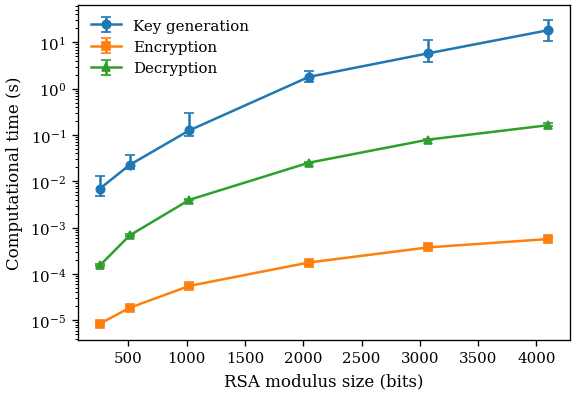

In [24]:
bits = rsa_summary_array[:, 0]

key_median = rsa_summary_array[:, 1]
key_q1 = rsa_summary_array[:, 2]
key_q3 = rsa_summary_array[:, 3]

enc_median = rsa_summary_array[:, 5]
enc_q1 = rsa_summary_array[:, 6]
enc_q3 = rsa_summary_array[:, 7]

dec_median = rsa_summary_array[:, 9]
dec_q1 = rsa_summary_array[:, 10]
dec_q3 = rsa_summary_array[:, 11]

plt.figure()

plt.errorbar(
    bits,
    key_median,
    yerr=[
        key_median - key_q1,
        key_q3 - key_median
    ],
    marker="o",
    capsize=3,
    label="Key generation"
)

plt.errorbar(
    bits,
    enc_median,
    yerr=[
        enc_median - enc_q1,
        enc_q3 - enc_median
    ],
    marker="s",
    capsize=3,
    label="Encryption"
)

plt.errorbar(
    bits,
    dec_median,
    yerr=[
        dec_median - dec_q1,
        dec_q3 - dec_median
    ],
    marker="^",
    capsize=3,
    label="Decryption"
)

plt.xlabel("RSA modulus size (bits)")
plt.ylabel("Computational time (s)")

plt.yscale("log")

plt.legend()

plt.tight_layout()

plt.savefig(
    "rsa_scaling.png",
    dpi=FIG_DPI
)

plt.savefig(
    "rsa_scaling.pdf"
)

plt.show()

In [25]:
FACTORIZATION_BITS = [
    24,
    28,
    32,
    36,
    40,
    44,
    48
]

FACTORIZATION_REPETITIONS = 20

FACTORIZATION_METHODS = [
    "trial_division",
    "fermat",
    "pollard_rho"
]

FACTORIZATION_TIME_LIMIT = 2.0

print("Factorization sizes:", FACTORIZATION_BITS)
print("Repetitions:", FACTORIZATION_REPETITIONS)

Factorization sizes: [24, 28, 32, 36, 40, 44, 48]
Repetitions: 20


In [26]:
start = time.perf_counter()

factorization_results = run_factorization_scaling_experiment(
    modulus_bits_values=FACTORIZATION_BITS,
    repetitions=FACTORIZATION_REPETITIONS,
    methods=FACTORIZATION_METHODS,
    seed=SEED,
    rounds=MILLER_RABIN_ROUNDS,
    time_limit_s=FACTORIZATION_TIME_LIMIT,
    max_iterations=None,
    max_restarts=20,
    verbose=True
)

factorization_total_time = (
    time.perf_counter() - start
)

print(
    "\nTotal factorization experiment time:",
    f"{factorization_total_time:.3f} s"
)

Factorization experiment: 24 bits
Completed in 0.02 s

Factorization experiment: 28 bits
Completed in 0.04 s

Factorization experiment: 32 bits
Completed in 0.12 s

Factorization experiment: 36 bits
Completed in 0.53 s

Factorization experiment: 40 bits
Completed in 1.89 s

Factorization experiment: 44 bits
Completed in 7.15 s

Factorization experiment: 48 bits
Completed in 30.14 s


Total factorization experiment time: 39.885 s


In [27]:
method_code = {
    "trial_division": 1,
    "fermat": 2,
    "pollard_rho": 3
}

status_code = {
    "success": 1,
    "timeout": 2,
    "max_iterations": 3,
    "max_restarts": 4,
    "no_nontrivial_factor": 5,
    "invalid_factor": 6
}

factorization_raw = np.array([
    [
        r["requested_modulus_bits"],
        r["actual_modulus_bits"],
        r["repetition"],
        method_code[r["method"]],
        r["method_seed"],
        r["p"],
        r["q"],
        r["n"],
        r["prime_gap"],
        r["normalized_gap"],
        int(r["success"]),
        -1 if r["factor_1"] is None else r["factor_1"],
        -1 if r["factor_2"] is None else r["factor_2"],
        r["iterations"],
        r["restarts"],
        r["elapsed_s"],
        status_code[r["status"]]
    ]
    for r in factorization_results
], dtype=object)

np.savetxt(
    "factorization_results.txt",
    factorization_raw,
    header=(
        "requested_bits actual_bits repetition method_code method_seed "
        "p q n prime_gap normalized_gap success factor_1 factor_2 "
        "iterations restarts elapsed_s status_code\n"
        "method_code: 1=trial_division 2=fermat 3=pollard_rho\n"
        "status_code: 1=success 2=timeout 3=max_iterations "
        "4=max_restarts 5=no_nontrivial_factor 6=invalid_factor"
    ),
    fmt=[
        "%d", "%d", "%d", "%d", "%d", "%d", "%d", "%d", "%d",
        "%.12e", "%d", "%d", "%d", "%d", "%d", "%.12e", "%d"
    ]
)

print("Factorization raw table:", factorization_raw.shape)

Factorization raw table: (420, 17)


In [28]:
factorization_summary = summarize_factorization(
    factorization_results,
    group_by=[
        "requested_modulus_bits",
        "method"
    ]
)

factorization_summary = sorted(
    factorization_summary,
    key=lambda x: (
        x["requested_modulus_bits"],
        x["method"]
    )
)

factorization_summary_array = np.array([
    [
        r["requested_modulus_bits"],
        method_code[r["method"]],
        r["n_total"],
        r["n_success"],
        r["success_rate"],
        r["n_timeout"],
        (
            np.nan
            if r["elapsed_s_median"] is None
            else r["elapsed_s_median"]
        ),
        (
            np.nan
            if r["elapsed_s_q1"] is None
            else r["elapsed_s_q1"]
        ),
        (
            np.nan
            if r["elapsed_s_q3"] is None
            else r["elapsed_s_q3"]
        ),
        (
            np.nan
            if r["iterations_median"] is None
            else r["iterations_median"]
        ),
        (
            np.nan
            if r["iterations_q1"] is None
            else r["iterations_q1"]
        ),
        (
            np.nan
            if r["iterations_q3"] is None
            else r["iterations_q3"]
        )
    ]
    for r in factorization_summary
], dtype=float)

np.savetxt(
    "factorization_summary.txt",
    factorization_summary_array,
    header=(
        "modulus_bits method_code "
        "n_total n_success success_rate n_timeout "
        "elapsed_median elapsed_q1 elapsed_q3 "
        "iterations_median iterations_q1 iterations_q3"
    ),
    fmt="%.12e"
)

print(factorization_summary_array)

[[2.40000000e+01 2.00000000e+00 2.00000000e+01 2.00000000e+01
  1.00000000e+00 0.00000000e+00 9.10000017e-06 6.65000061e-06
  3.20000008e-05 1.15000000e+01 5.75000000e+00 5.42500000e+01]
 [2.40000000e+01 3.00000000e+00 2.00000000e+01 2.00000000e+01
  1.00000000e+00 0.00000000e+00 5.42499984e-05 4.02249980e-05
  7.14749985e-05 4.25000000e+01 2.77500000e+01 5.85000000e+01]
 [2.40000000e+01 1.00000000e+00 2.00000000e+01 2.00000000e+01
  1.00000000e+00 0.00000000e+00 4.88399999e-04 3.70075001e-04
  6.84050002e-04 1.41800000e+03 1.27350000e+03 1.60950000e+03]
 [2.80000000e+01 2.00000000e+00 2.00000000e+01 2.00000000e+01
  1.00000000e+00 0.00000000e+00 2.33499995e-05 1.25249999e-05
  8.14499990e-05 7.70000000e+01 2.30000000e+01 2.41750000e+02]
 [2.80000000e+01 3.00000000e+00 2.00000000e+01 2.00000000e+01
  1.00000000e+00 0.00000000e+00 5.48500011e-05 4.37750014e-05
  9.03250002e-05 5.90000000e+01 4.87500000e+01 9.90000000e+01]
 [2.80000000e+01 1.00000000e+00 2.00000000e+01 2.00000000e+01
  1

In [29]:
# Use one record per semiprime to avoid duplicating the same gap for each method.
factorization_instances = [
    r for r in factorization_results
    if r["method"] == "trial_division"
]

factorization_gap_summary = summarize_records(
    factorization_instances,
    group_by=["requested_modulus_bits"],
    metrics=["normalized_gap"]
)

factorization_gap_summary = sorted(
    factorization_gap_summary,
    key=lambda x: x["requested_modulus_bits"]
)

factorization_gap_summary_array = np.array([
    [
        r["requested_modulus_bits"],
        r["normalized_gap_median"],
        r["normalized_gap_q1"],
        r["normalized_gap_q3"],
        r["normalized_gap_iqr"]
    ]
    for r in factorization_gap_summary
], dtype=float)

np.savetxt(
    "factorization_gap_summary.txt",
    factorization_gap_summary_array,
    header="modulus_bits gap_median gap_q1 gap_q3 gap_iqr",
    fmt="%.12e"
)

print(factorization_gap_summary_array)

[[24.          0.1663052   0.11447071  0.37322453  0.25875382]
 [28.          0.20894602  0.11981824  0.39562286  0.27580462]
 [32.          0.13866151  0.07530821  0.35110978  0.27580157]
 [36.          0.19336153  0.1169506   0.32653702  0.20958642]
 [40.          0.12247392  0.07739271  0.26530037  0.18790765]
 [44.          0.19588078  0.05247628  0.36095425  0.30847798]
 [48.          0.14215559  0.12609437  0.33780689  0.21171251]]


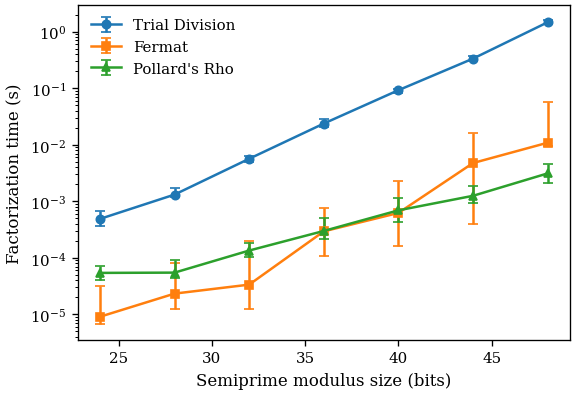

In [30]:
plt.figure()

labels = {
    1: "Trial Division",
    2: "Fermat",
    3: "Pollard's Rho"
}

markers = {
    1: "o",
    2: "s",
    3: "^"
}

for code in [1, 2, 3]:

    data = factorization_summary_array[
        factorization_summary_array[:, 1] == code
    ]

    x = data[:, 0]

    median = data[:, 6]
    q1 = data[:, 7]
    q3 = data[:, 8]

    valid = np.isfinite(median)

    plt.errorbar(
        x[valid],
        median[valid],
        yerr=[
            median[valid] - q1[valid],
            q3[valid] - median[valid]
        ],
        marker=markers[code],
        capsize=3,
        label=labels[code]
    )

plt.xlabel("Semiprime modulus size (bits)")
plt.ylabel("Factorization time (s)")

plt.yscale("log")

plt.legend()

plt.tight_layout()

plt.savefig(
    "factorization_scaling.png",
    dpi=FIG_DPI
)

plt.savefig(
    "factorization_scaling.pdf"
)

plt.show()

### Factorization success result

The corrected execution produced 419 successful factorizations in 420
attempts. Trial Division reached the two-second limit once at 48 bits,
resulting in a success rate of 0.95 for that configuration. Fermat
Factorization and Pollard's Rho achieved a success rate of 1.0 in every
configuration. The diagnostic success-rate figure is provided at the end of
the notebook and should not replace the principal scaling figures in the
article.

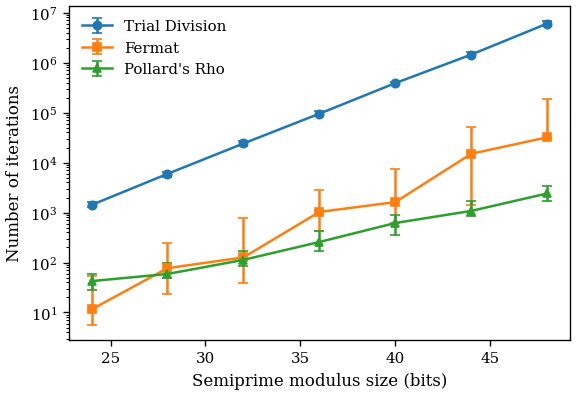

In [31]:
plt.figure()

for code in [1, 2, 3]:

    data = factorization_summary_array[
        factorization_summary_array[:, 1] == code
    ]

    x = data[:, 0]

    median = data[:, 9]
    q1 = data[:, 10]
    q3 = data[:, 11]

    valid = np.isfinite(median)

    plt.errorbar(
        x[valid],
        median[valid],
        yerr=[
            median[valid] - q1[valid],
            q3[valid] - median[valid]
        ],
        marker=markers[code],
        capsize=3,
        label=labels[code]
    )

plt.xlabel("Semiprime modulus size (bits)")
plt.ylabel("Number of iterations")

plt.yscale("log")

plt.legend()

plt.tight_layout()

plt.savefig(
    "factorization_iterations.png",
    dpi=FIG_DPI
)

plt.savefig(
    "factorization_iterations.pdf"
)

plt.show()

In [32]:
complexity_fit_rows = []

for code, theoretical_slope in [(1, 0.50), (3, 0.25)]:
    data = factorization_summary_array[
        factorization_summary_array[:, 1] == code
    ]

    x = data[:, 0]
    y = np.log2(data[:, 9])

    slope, intercept = np.polyfit(x, y, 1)
    predicted = slope * x + intercept

    r_squared = 1.0 - np.sum((y - predicted) ** 2) / np.sum(
        (y - np.mean(y)) ** 2
    )

    complexity_fit_rows.append([
        code,
        slope,
        theoretical_slope,
        r_squared
    ])

complexity_fit_array = np.array(complexity_fit_rows, dtype=float)

np.savetxt(
    "factorization_complexity_fit.txt",
    complexity_fit_array,
    header=(
        "method_code observed_log2_slope theoretical_log2_slope r_squared\n"
        "method_code: 1=trial_division 3=pollard_rho"
    ),
    fmt=["%d", "%.12e", "%.12e", "%.12e"]
)

print(complexity_fit_array)

[[1.         0.50041351 0.5        0.99991295]
 [3.         0.25277286 0.25       0.9905031 ]]


In [33]:
GAP_BITS = [
    32,
    36,
    40,
    44,
    48
]

NORMALIZED_GAPS = [
    0.001,
    0.005,
    0.01,
    0.05,
    0.10,
    0.25,
    0.50
]

GAP_METHODS = [
    "fermat",
    "pollard_rho"
]

GAP_REPETITIONS = 15

GAP_TIME_LIMIT = 2.0

print("Modulus sizes:", GAP_BITS)
print("Normalized gaps:", NORMALIZED_GAPS)
print("Repetitions:", GAP_REPETITIONS)

Modulus sizes: [32, 36, 40, 44, 48]
Normalized gaps: [0.001, 0.005, 0.01, 0.05, 0.1, 0.25, 0.5]
Repetitions: 15


In [34]:
start = time.perf_counter()

gap_results = run_gap_experiment(
    modulus_bits_values=GAP_BITS,
    target_normalized_gaps=NORMALIZED_GAPS,
    repetitions=GAP_REPETITIONS,
    methods=GAP_METHODS,
    seed=SEED,
    rounds=MILLER_RABIN_ROUNDS,
    time_limit_s=GAP_TIME_LIMIT,
    max_iterations=None,
    max_restarts=20,
    verbose=True
)

gap_total_time = time.perf_counter() - start

print(
    "\nTotal prime-gap experiment time:",
    f"{gap_total_time:.3f} s"
)

Gap experiment: 32 bits, G = 0.001
Completed in 0.00 s

Gap experiment: 32 bits, G = 0.005
Completed in 0.01 s

Gap experiment: 32 bits, G = 0.01
Completed in 0.00 s

Gap experiment: 32 bits, G = 0.05
Completed in 0.00 s

Gap experiment: 32 bits, G = 0.1
Completed in 0.01 s

Gap experiment: 32 bits, G = 0.25
Completed in 0.01 s

Gap experiment: 32 bits, G = 0.5
Completed in 0.01 s

Gap experiment: 36 bits, G = 0.001
Completed in 0.01 s

Gap experiment: 36 bits, G = 0.005
Completed in 0.01 s

Gap experiment: 36 bits, G = 0.01
Completed in 0.01 s

Gap experiment: 36 bits, G = 0.05
Completed in 0.05 s

Gap experiment: 36 bits, G = 0.1
Completed in 0.01 s

Gap experiment: 36 bits, G = 0.25
Completed in 0.03 s

Gap experiment: 36 bits, G = 0.5
Completed in 0.05 s

Gap experiment: 40 bits, G = 0.001
Completed in 0.01 s

Gap experiment: 40 bits, G = 0.005
Completed in 0.02 s

Gap experiment: 40 bits, G = 0.01
Completed in 0.02 s

Gap experiment: 40 bits, G = 0.05
Completed in 0.02 s

Gap expe

In [35]:
gap_method_code = {
    "fermat": 1,
    "pollard_rho": 2
}

gap_status_code = {
    "success": 1,
    "timeout": 2,
    "max_iterations": 3,
    "max_restarts": 4,
    "no_nontrivial_factor": 5,
    "invalid_factor": 6
}

gap_raw = np.array([
    [
        r["requested_modulus_bits"],
        r["actual_modulus_bits"],
        r["target_normalized_gap"],
        r["actual_normalized_gap"],
        r["repetition"],
        gap_method_code[r["method"]],
        r["method_seed"],
        r["p"],
        r["q"],
        r["n"],
        r["prime_gap"],
        int(r["success"]),
        -1 if r["factor_1"] is None else r["factor_1"],
        -1 if r["factor_2"] is None else r["factor_2"],
        r["iterations"],
        r["restarts"],
        r["elapsed_s"],
        gap_status_code[r["status"]]
    ]
    for r in gap_results
], dtype=object)

np.savetxt(
    "prime_gap_results.txt",
    gap_raw,
    header=(
        "requested_bits actual_bits target_gap actual_gap repetition "
        "method_code method_seed p q n prime_gap success factor_1 factor_2 "
        "iterations restarts elapsed_s status_code\n"
        "method_code: 1=fermat 2=pollard_rho\n"
        "status_code: 1=success 2=timeout 3=max_iterations "
        "4=max_restarts 5=no_nontrivial_factor 6=invalid_factor"
    ),
    fmt=[
        "%d", "%d", "%.12e", "%.12e", "%d", "%d", "%d", "%d",
        "%d", "%d", "%d", "%d", "%d", "%d", "%d", "%d",
        "%.12e", "%d"
    ]
)

print("Prime-gap raw table:", gap_raw.shape)

Prime-gap raw table: (1050, 18)


In [36]:
gap_summary = summarize_factorization(
    gap_results,
    group_by=[
        "requested_modulus_bits",
        "target_normalized_gap",
        "method"
    ]
)

gap_summary = sorted(
    gap_summary,
    key=lambda x: (
        x["requested_modulus_bits"],
        x["target_normalized_gap"],
        x["method"]
    )
)

gap_summary_array = np.array([
    [
        r["requested_modulus_bits"],
        r["target_normalized_gap"],
        gap_method_code[r["method"]],
        r["n_total"],
        r["n_success"],
        r["success_rate"],
        r["n_timeout"],
        (
            np.nan
            if r["elapsed_s_median"] is None
            else r["elapsed_s_median"]
        ),
        (
            np.nan
            if r["elapsed_s_q1"] is None
            else r["elapsed_s_q1"]
        ),
        (
            np.nan
            if r["elapsed_s_q3"] is None
            else r["elapsed_s_q3"]
        ),
        (
            np.nan
            if r["iterations_median"] is None
            else r["iterations_median"]
        ),
        (
            np.nan
            if r["iterations_q1"] is None
            else r["iterations_q1"]
        ),
        (
            np.nan
            if r["iterations_q3"] is None
            else r["iterations_q3"]
        )
    ]
    for r in gap_summary
], dtype=float)

np.savetxt(
    "prime_gap_summary.txt",
    gap_summary_array,
    header=(
        "modulus_bits target_gap method_code "
        "n_total n_success success_rate n_timeout "
        "elapsed_median elapsed_q1 elapsed_q3 "
        "iterations_median iterations_q1 iterations_q3"
    ),
    fmt="%.12e"
)

print(gap_summary_array)

[[3.20000000e+01 1.00000000e-03 1.00000000e+00 1.50000000e+01
  1.50000000e+01 1.00000000e+00 0.00000000e+00 1.30000262e-06
  1.20000186e-06 1.84999953e-06 1.00000000e+00 1.00000000e+00
  1.00000000e+00]
 [3.20000000e+01 1.00000000e-03 2.00000000e+00 1.50000000e+01
  1.50000000e+01 1.00000000e+00 0.00000000e+00 1.71700001e-04
  1.11699999e-04 2.66000001e-04 1.29000000e+02 8.65000000e+01
  2.14000000e+02]
 [3.20000000e+01 5.00000000e-03 1.00000000e+00 1.50000000e+01
  1.50000000e+01 1.00000000e+00 0.00000000e+00 1.50000051e-06
  1.29999898e-06 2.59999979e-06 1.00000000e+00 1.00000000e+00
  1.00000000e+00]
 [3.20000000e+01 5.00000000e-03 2.00000000e+00 1.50000000e+01
  1.50000000e+01 1.00000000e+00 0.00000000e+00 2.65300001e-04
  1.78650002e-04 3.61850001e-04 1.78000000e+02 1.40000000e+02
  2.87500000e+02]
 [3.20000000e+01 1.00000000e-02 1.00000000e+00 1.50000000e+01
  1.50000000e+01 1.00000000e+00 0.00000000e+00 1.19999822e-06
  1.10000110e-06 1.20000186e-06 1.00000000e+00 1.00000000e+0

In [37]:
# Fermat and Pollard's Rho use the same semiprime in each repetition.
# Keep one record per semiprime when summarizing the achieved separation.
gap_instances = [
    r for r in gap_results
    if r["method"] == "fermat"
]

gap_actual_summary = summarize_records(
    gap_instances,
    group_by=[
        "requested_modulus_bits",
        "target_normalized_gap"
    ],
    metrics=["actual_normalized_gap"]
)

gap_actual_summary = sorted(
    gap_actual_summary,
    key=lambda x: (
        x["requested_modulus_bits"],
        x["target_normalized_gap"]
    )
)

gap_actual_summary_array = []

for row in gap_actual_summary:
    bits_value = row["requested_modulus_bits"]
    target_gap = row["target_normalized_gap"]

    values = np.array([
        r["actual_normalized_gap"]
        for r in gap_instances
        if (
            r["requested_modulus_bits"] == bits_value
            and np.isclose(r["target_normalized_gap"], target_gap)
        )
    ])

    relative_errors = np.abs(values - target_gap) / target_gap

    gap_actual_summary_array.append([
        bits_value,
        target_gap,
        row["actual_normalized_gap_median"],
        row["actual_normalized_gap_q1"],
        row["actual_normalized_gap_q3"],
        np.median(relative_errors),
        np.max(relative_errors)
    ])

gap_actual_summary_array = np.array(
    gap_actual_summary_array,
    dtype=float
)

np.savetxt(
    "prime_gap_actual_summary.txt",
    gap_actual_summary_array,
    header=(
        "modulus_bits target_gap actual_median actual_q1 actual_q3 "
        "relative_error_median relative_error_max"
    ),
    fmt="%.12e"
)

gap_actual_lookup = {
    (int(row[0]), row[1]): row[2:5]
    for row in gap_actual_summary_array
}

print(gap_actual_summary_array)

[[3.20000000e+01 1.00000000e-03 1.12961547e-03 1.04418848e-03
  1.16533113e-03 1.29615465e-01 4.69679906e-01]
 [3.20000000e+01 5.00000000e-03 5.04623947e-03 5.02298076e-03
  5.11447186e-03 9.24789377e-03 7.11834061e-02]
 [3.20000000e+01 1.00000000e-02 1.00741702e-02 1.00254044e-02
  1.01546578e-02 7.41702316e-03 2.51964677e-02]
 [3.20000000e+01 5.00000000e-02 5.01034428e-02 5.00565806e-02
  5.01780190e-02 2.06885584e-03 6.80404311e-03]
 [3.20000000e+01 1.00000000e-01 1.00078257e-01 1.00029919e-01
  1.00251621e-01 7.82566992e-04 9.05865845e-03]
 [3.20000000e+01 2.50000000e-01 2.50113576e-01 2.50057250e-01
  2.50295278e-01 4.54304711e-04 3.44266306e-03]
 [3.20000000e+01 5.00000000e-01 5.00086355e-01 5.00013969e-01
  5.00294017e-01 1.72710975e-04 1.04066853e-03]
 [3.60000000e+01 1.00000000e-03 1.08359933e-03 1.05003674e-03
  1.09443394e-03 8.35993286e-02 1.39231077e-01]
 [3.60000000e+01 5.00000000e-03 5.02291549e-03 5.00693146e-03
  5.05389112e-03 4.58309735e-03 2.31633597e-02]
 [3.600000

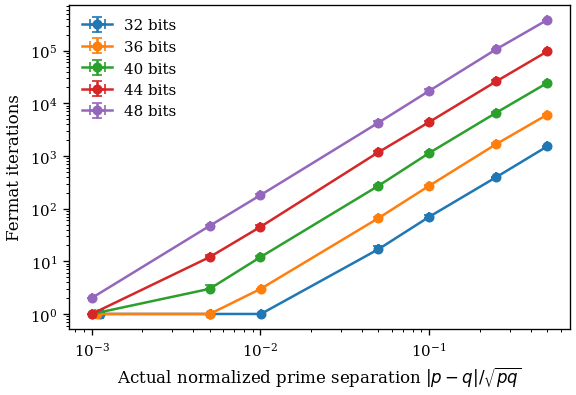

In [38]:
plt.figure()

for bits_value in GAP_BITS:
    data = gap_summary_array[
        (gap_summary_array[:, 0] == bits_value)
        &
        (gap_summary_array[:, 2] == 1)
    ]

    actual = np.array([
        gap_actual_lookup[(bits_value, target)]
        for target in data[:, 1]
    ])

    x = actual[:, 0]
    x_q1 = actual[:, 1]
    x_q3 = actual[:, 2]

    median = data[:, 10]
    q1 = data[:, 11]
    q3 = data[:, 12]

    valid = np.isfinite(median)

    plt.errorbar(
        x[valid],
        median[valid],
        xerr=[
            x[valid] - x_q1[valid],
            x_q3[valid] - x[valid]
        ],
        yerr=[
            median[valid] - q1[valid],
            q3[valid] - median[valid]
        ],
        marker="o",
        capsize=3,
        label=f"{bits_value} bits"
    )

plt.xlabel(
    r"Actual normalized prime separation $|p-q|/\sqrt{pq}$"
)
plt.ylabel("Fermat iterations")

plt.xscale("log")
plt.yscale("log")
plt.legend()
plt.tight_layout()

plt.savefig("fermat_prime_separation.png", dpi=FIG_DPI)
plt.savefig("fermat_prime_separation.pdf")
plt.show()

In [39]:
# Exact Fermat count and empirical dependence on the achieved separation.
for record in gap_instances:
    p = record["p"]
    q = record["q"]
    n = record["n"]

    exact_iterations = (
        (p + q) // 2
        - int(np.ceil(np.sqrt(n)))
        + 1
    )

    assert exact_iterations == record["iterations"]

fermat_gap_fit_rows = []

for bits_value in GAP_BITS:
    summary_data = gap_summary_array[
        (gap_summary_array[:, 0] == bits_value)
        &
        (gap_summary_array[:, 2] == 1)
        &
        (gap_summary_array[:, 1] >= 0.01)
    ]

    actual_x = np.array([
        gap_actual_lookup[(bits_value, target)][0]
        for target in summary_data[:, 1]
    ])

    y = summary_data[:, 10]

    exponent, intercept = np.polyfit(
        np.log2(actual_x),
        np.log2(y),
        1
    )

    predicted = exponent * np.log2(actual_x) + intercept

    r_squared = 1.0 - np.sum(
        (np.log2(y) - predicted) ** 2
    ) / np.sum(
        (np.log2(y) - np.mean(np.log2(y))) ** 2
    )

    fermat_gap_fit_rows.append([
        bits_value,
        exponent,
        r_squared
    ])

fermat_gap_fit_array = np.array(
    fermat_gap_fit_rows,
    dtype=float
)

np.savetxt(
    "fermat_gap_power_fit.txt",
    fermat_gap_fit_array,
    header="modulus_bits gap_exponent r_squared",
    fmt=["%d", "%.12e", "%.12e"]
)

print(fermat_gap_fit_array)

[[32.          1.88295283  0.99936034]
 [36.          1.95935697  0.99984975]
 [40.          1.95438267  0.99984862]
 [44.          1.96076797  0.9997501 ]
 [48.          1.96718505  0.9998771 ]]


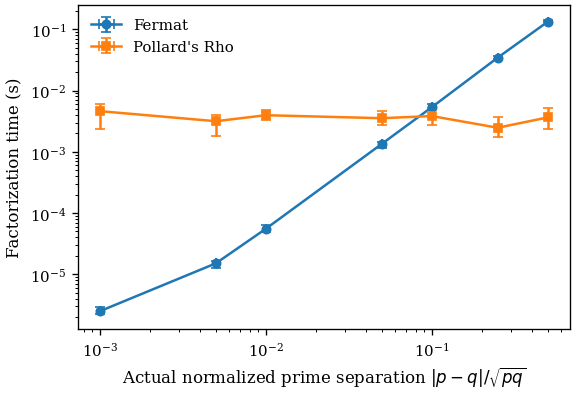

In [40]:
SELECTED_BITS = 48

plt.figure()

for code, label, marker in [
    (1, "Fermat", "o"),
    (2, "Pollard's Rho", "s")
]:
    data = gap_summary_array[
        (gap_summary_array[:, 0] == SELECTED_BITS)
        &
        (gap_summary_array[:, 2] == code)
    ]

    actual = np.array([
        gap_actual_lookup[(SELECTED_BITS, target)]
        for target in data[:, 1]
    ])

    x = actual[:, 0]
    x_q1 = actual[:, 1]
    x_q3 = actual[:, 2]

    median = data[:, 7]
    q1 = data[:, 8]
    q3 = data[:, 9]

    valid = np.isfinite(median)

    plt.errorbar(
        x[valid],
        median[valid],
        xerr=[
            x[valid] - x_q1[valid],
            x_q3[valid] - x[valid]
        ],
        yerr=[
            median[valid] - q1[valid],
            q3[valid] - median[valid]
        ],
        marker=marker,
        capsize=3,
        label=label
    )

plt.xlabel(
    r"Actual normalized prime separation $|p-q|/\sqrt{pq}$"
)
plt.ylabel("Factorization time (s)")

plt.xscale("log")
plt.yscale("log")
plt.legend()
plt.tight_layout()

plt.savefig("prime_separation_comparison.png", dpi=FIG_DPI)
plt.savefig("prime_separation_comparison.pdf")
plt.show()

In [41]:
fermat_matrix = np.full(
    (
        len(GAP_BITS),
        len(NORMALIZED_GAPS)
    ),
    np.nan
)

for i, bits_value in enumerate(GAP_BITS):

    for j, gap_value in enumerate(
        NORMALIZED_GAPS
    ):

        data = gap_summary_array[
            (gap_summary_array[:, 0] == bits_value)
            &
            (
                np.isclose(
                    gap_summary_array[:, 1],
                    gap_value
                )
            )
            &
            (gap_summary_array[:, 2] == 1)
        ]

        if len(data) > 0:

            fermat_matrix[i, j] = data[0, 10]

print(fermat_matrix)

np.savetxt(
    "fermat_iteration_matrix.txt",
    fermat_matrix,
    header=(
        "Rows correspond to GAP_BITS = "
        + str(GAP_BITS)
        + "\nColumns correspond to NORMALIZED_GAPS = "
        + str(NORMALIZED_GAPS)
    ),
    fmt="%.12e"
)

[[1.00000e+00 1.00000e+00 1.00000e+00 1.70000e+01 7.00000e+01 3.98000e+02
  1.52100e+03]
 [1.00000e+00 1.00000e+00 3.00000e+00 6.60000e+01 2.72000e+02 1.68800e+03
  6.09000e+03]
 [1.00000e+00 3.00000e+00 1.20000e+01 2.71000e+02 1.14000e+03 6.65500e+03
  2.43370e+04]
 [1.00000e+00 1.20000e+01 4.50000e+01 1.17700e+03 4.41000e+03 2.61930e+04
  9.65360e+04]
 [2.00000e+00 4.70000e+01 1.80000e+02 4.28000e+03 1.72290e+04 1.06800e+05
  3.83015e+05]]


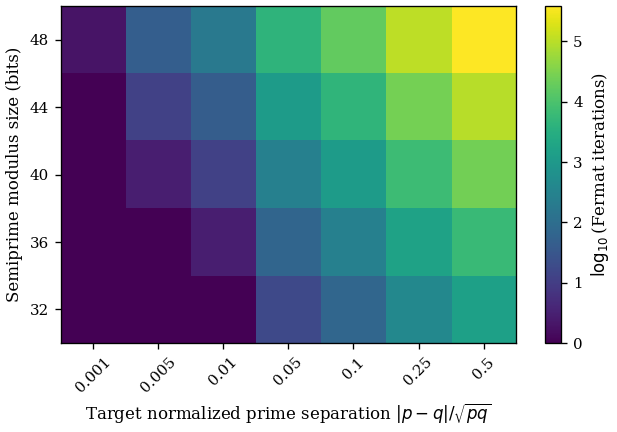

In [42]:
plt.figure(figsize=(5.5, 3.8))

log_matrix = np.log10(fermat_matrix)

image = plt.imshow(
    log_matrix,
    origin="lower",
    aspect="auto",
    cmap="viridis"
)

plt.xticks(
    np.arange(len(NORMALIZED_GAPS)),
    [str(value) for value in NORMALIZED_GAPS],
    rotation=45
)

plt.yticks(
    np.arange(len(GAP_BITS)),
    [str(value) for value in GAP_BITS]
)

plt.xlabel(
    r"Target normalized prime separation $|p-q|/\sqrt{pq}$"
)
plt.ylabel("Semiprime modulus size (bits)")

colorbar = plt.colorbar(image)
colorbar.set_label(r"$\log_{10}$(Fermat iterations)")

plt.tight_layout()
plt.savefig("fermat_computational_map.png", dpi=FIG_DPI)
plt.savefig("fermat_computational_map.pdf")
plt.show()

In [43]:
computational_times = np.array([
    [
        rsa_total_time,
        factorization_total_time,
        gap_total_time,
        (
            rsa_total_time
            +
            factorization_total_time
            +
            gap_total_time
        )
    ]
])

np.savetxt(
    "computational_times.txt",
    computational_times,
    header=(
        "rsa_total_s "
        "factorization_total_s "
        "prime_gap_total_s "
        "overall_total_s"
    ),
    fmt="%.6f"
)

print(
    "RSA experiment:",
    f"{rsa_total_time:.3f} s"
)

print(
    "Factorization experiment:",
    f"{factorization_total_time:.3f} s"
)

print(
    "Prime-gap experiment:",
    f"{gap_total_time:.3f} s"
)

print(
    "Overall computational time:",
    f"{computational_times[0, 3]:.3f} s"
)

RSA experiment: 1104.144 s
Factorization experiment: 39.885 s
Prime-gap experiment: 4.418 s
Overall computational time: 1148.447 s


In [44]:
if rsa_results is not None:
    assert all(
        r["message_verified"]
        for r in rsa_results
    )
else:
    assert rsa_summary_array.shape == (len(RSA_BITS), 13)

for r in factorization_results:
    if r["success"]:
        assert r["factor_1"] * r["factor_2"] == r["n"]

for r in gap_results:
    if r["success"]:
        assert r["factor_1"] * r["factor_2"] == r["n"]

for r in gap_instances:
    recalculated_gap = abs(r["p"] - r["q"]) / np.sqrt(r["n"])
    assert np.isclose(recalculated_gap, r["actual_normalized_gap"])

print("All computational results validated.")

All computational results validated.


In [45]:
import os

files = sorted(
    file
    for file in os.listdir(".")
    if (
        file.endswith(".txt")
        or file.endswith(".png")
        or file.endswith(".pdf")
    )
)

for file in files:
    print(file)

HISTORICO_PAINEL_FIGURAS_RECEBIDAS.png
LEIA-ME.txt
MANIFESTO_SHA256.txt
OBSOLETO_factorization_success_rate.png
PAINEL_FIGURAS_VALIDAS.png
computational_times.txt
factorization_complexity_fit.txt
factorization_gap_summary.txt
factorization_iterations.pdf
factorization_iterations.png
factorization_pilot.txt
factorization_results.txt
factorization_scaling.pdf
factorization_scaling.png
factorization_success_rate.png
factorization_success_rate_observed.png
factorization_summary.txt
fermat_computational_map.pdf
fermat_computational_map.png
fermat_gap_power_fit.txt
fermat_iteration_matrix.txt
fermat_prime_separation.pdf
fermat_prime_separation.png
prime_gap_actual_summary.txt
prime_gap_comparison.txt
prime_gap_pilot.txt
prime_gap_results.txt
prime_gap_summary.txt
prime_separation_comparison.pdf
prime_separation_comparison.png
rsa_pilot.txt
rsa_results.txt
rsa_scaling.pdf
rsa_scaling.png
rsa_summary.txt
system_metadata.txt


## Computational experiments completed

Three numerical experiments were performed:

1. textbook RSA key generation, encryption, and decryption scaling;
2. integer factorization scaling using Trial Division, Fermat Factorization,
   and Pollard's Rho;
3. influence of the achieved normalized prime-factor separation on
   factorization cost.

Raw numerical results, achieved-gap summaries, complexity fits, computational
times, and publication figures are saved in the same directory as the notebook.

## Diagnostic success-rate figure

This diagnostic figure records the corrected result: 419 successes in 420
factorization attempts. Trial Division at 48 bits achieved 19/20 successes
(95%), with one timeout. The previously generated constant success-rate figure
is obsolete and is retained outside the notebook only for historical
traceability.

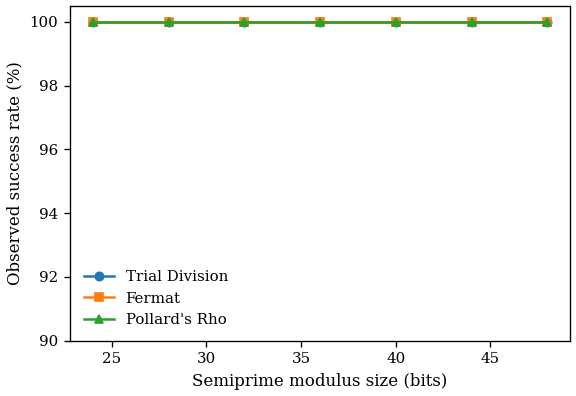

In [46]:
success_summary = np.atleast_2d(
    np.loadtxt("factorization_summary.txt")
)

plt.figure()

for code in [1, 2, 3]:
    data = success_summary[
        success_summary[:, 1] == code
    ]

    plt.plot(
        data[:, 0],
        100.0 * data[:, 4],
        marker=markers[code],
        label=labels[code]
    )

plt.xlabel("Semiprime modulus size (bits)")
plt.ylabel("Observed success rate (%)")
plt.ylim(90, 100.5)
plt.legend(loc="lower left")
plt.tight_layout()

plt.savefig(
    "factorization_success_rate_observed.png",
    dpi=FIG_DPI
)
plt.savefig("factorization_success_rate_observed.pdf")
plt.show()

In [49]:
# FINAL COMPUTATIONAL ENVIRONMENT REPORT

from datetime import datetime
from pathlib import Path
import contextlib
import importlib.metadata
import io
import json
import os
import platform
import shutil
import struct
import subprocess
import sys
import time


def bytes_to_gib(value):
    """Convert bytes to GiB."""
    return value / (1024 ** 3)


def run_command(command):
    """Run an external command without interrupting the report."""
    try:
        result = subprocess.run(
            command,
            capture_output=True,
            text=True,
            timeout=20,
            check=False,
        )
        output = result.stdout.strip()
        return output if output else "Not available"
    except Exception:
        return "Not available"


def package_version(package_name):
    """Return the installed package version."""
    try:
        return importlib.metadata.version(package_name)
    except importlib.metadata.PackageNotFoundError:
        return "Not installed"


# ---------------------------------------------------------------------
# Execution time
# ---------------------------------------------------------------------

notebook_end_datetime = datetime.now().astimezone()

if "NOTEBOOK_START_TIMER" in globals():
    notebook_elapsed_seconds = time.perf_counter() - NOTEBOOK_START_TIMER
    notebook_start_datetime = NOTEBOOK_START_DATETIME
else:
    notebook_elapsed_seconds = None
    notebook_start_datetime = None


# ---------------------------------------------------------------------
# CPU information
# ---------------------------------------------------------------------

cpu_model = platform.processor().strip()

if not cpu_model and platform.system() == "Windows":
    cpu_model = run_command([
        "powershell",
        "-NoProfile",
        "-Command",
        "(Get-CimInstance Win32_Processor | "
        "Select-Object -ExpandProperty Name) -join '; '"
    ])

if not cpu_model:
    cpu_model = "Not available"


# ---------------------------------------------------------------------
# Computer manufacturer and model
# ---------------------------------------------------------------------

computer_model = "Not available"

if platform.system() == "Windows":
    computer_model = run_command([
        "powershell",
        "-NoProfile",
        "-Command",
        "$computer = Get-CimInstance Win32_ComputerSystem; "
        "'{0} {1}' -f $computer.Manufacturer, $computer.Model"
    ])


# ---------------------------------------------------------------------
# Memory, CPU cores and frequency
# ---------------------------------------------------------------------

physical_cores = "Not available"
logical_cores = os.cpu_count() or "Not available"
cpu_frequency_current = "Not available"
cpu_frequency_maximum = "Not available"
ram_total_gib = "Not available"
ram_available_gib = "Not available"

try:
    import psutil

    physical_cores = psutil.cpu_count(logical=False)
    logical_cores = psutil.cpu_count(logical=True)

    memory = psutil.virtual_memory()
    ram_total_gib = f"{bytes_to_gib(memory.total):.3f}"
    ram_available_gib = f"{bytes_to_gib(memory.available):.3f}"

    frequency = psutil.cpu_freq()
    if frequency is not None:
        cpu_frequency_current = f"{frequency.current:.2f} MHz"
        cpu_frequency_maximum = f"{frequency.max:.2f} MHz"

except ImportError:
    pass


# ---------------------------------------------------------------------
# Disk information
# ---------------------------------------------------------------------

disk = shutil.disk_usage(Path.cwd())
disk_total_gib = bytes_to_gib(disk.total)
disk_free_gib = bytes_to_gib(disk.free)


# ---------------------------------------------------------------------
# GPU information, when an NVIDIA GPU is available
# ---------------------------------------------------------------------

gpu_information = run_command([
    "nvidia-smi",
    "--query-gpu=name,memory.total,driver_version",
    "--format=csv,noheader"
])


# ---------------------------------------------------------------------
# Important package versions
# ---------------------------------------------------------------------

important_packages = [
    "numpy",
    "scipy",
    "pandas",
    "matplotlib",
    "sympy",
    "psutil",
    "ipython",
    "ipykernel",
    "jupyter",
    "jupyterlab",
    "notebook",
]

package_versions = {
    name: package_version(name)
    for name in important_packages
}


# ---------------------------------------------------------------------
# NumPy, BLAS and LAPACK configuration
# ---------------------------------------------------------------------

numpy_configuration = "Not available"

try:
    import numpy as np

    numpy_buffer = io.StringIO()

    with contextlib.redirect_stdout(numpy_buffer):
        np.__config__.show()

    numpy_configuration = numpy_buffer.getvalue().strip()

except Exception as error:
    numpy_configuration = f"Could not obtain NumPy configuration: {error}"


# ---------------------------------------------------------------------
# Thread-related environment variables
# ---------------------------------------------------------------------

thread_variables = {
    name: os.environ.get(name, "Not explicitly defined")
    for name in [
        "OMP_NUM_THREADS",
        "MKL_NUM_THREADS",
        "OPENBLAS_NUM_THREADS",
        "NUMEXPR_NUM_THREADS",
    ]
}


# ---------------------------------------------------------------------
# Build the report
# ---------------------------------------------------------------------

report = {
    "report_generated_at": notebook_end_datetime.isoformat(),
    "notebook_execution_started_at": (
        notebook_start_datetime.isoformat()
        if notebook_start_datetime is not None
        else "Start timer was not executed"
    ),
    "notebook_execution_finished_at": notebook_end_datetime.isoformat(),
    "notebook_total_runtime_seconds": (
        round(notebook_elapsed_seconds, 6)
        if notebook_elapsed_seconds is not None
        else "Not available"
    ),
    "notebook_total_runtime_minutes": (
        round(notebook_elapsed_seconds / 60, 6)
        if notebook_elapsed_seconds is not None
        else "Not available"
    ),
    "computer_manufacturer_and_model": computer_model,
    "operating_system": platform.system(),
    "operating_system_release": platform.release(),
    "operating_system_version": platform.version(),
    "system_platform": platform.platform(),
    "machine_architecture": platform.machine(),
    "processor_architecture_bits": struct.calcsize("P") * 8,
    "cpu_model": cpu_model,
    "physical_cpu_cores": physical_cores,
    "logical_cpu_cores": logical_cores,
    "cpu_frequency_current": cpu_frequency_current,
    "cpu_frequency_maximum": cpu_frequency_maximum,
    "total_ram_gib": ram_total_gib,
    "available_ram_at_report_time_gib": ram_available_gib,
    "disk_total_gib": round(disk_total_gib, 3),
    "disk_free_at_report_time_gib": round(disk_free_gib, 3),
    "python_version": sys.version.replace("\n", " "),
    "python_implementation": platform.python_implementation(),
    "conda_environment": os.environ.get(
        "CONDA_DEFAULT_ENV",
        "Not running inside a named Conda environment",
    ),
    "nvidia_gpu": gpu_information,
    "important_package_versions": package_versions,
    "thread_environment_variables": thread_variables,
}


report_lines = [
    "COMPUTATIONAL ENVIRONMENT REPORT",
    "=" * 80,
]

for key, value in report.items():
    if isinstance(value, dict):
        report_lines.append("")
        report_lines.append(key.upper())
        report_lines.append("-" * 80)

        for subkey, subvalue in value.items():
            report_lines.append(f"{subkey}: {subvalue}")
    else:
        report_lines.append(f"{key}: {value}")

report_lines.extend([
    "",
    "NUMPY, BLAS AND LAPACK CONFIGURATION",
    "-" * 80,
    numpy_configuration,
])

report_text = "\n".join(report_lines)


# ---------------------------------------------------------------------
# Save all installed packages
# ---------------------------------------------------------------------

installed_packages = []

for distribution in importlib.metadata.distributions():
    package_name = (
        distribution.metadata.get("Name")
        or distribution.metadata.get("Summary")
        or "Unknown"
    )
    installed_packages.append(
        f"{package_name}=={distribution.version}"
    )

installed_packages = sorted(
    set(installed_packages),
    key=str.lower,
)


# ---------------------------------------------------------------------
# Write the output files
# ---------------------------------------------------------------------

Path("computational_environment_report.txt").write_text(
    report_text,
    encoding="utf-8",
)

Path("computational_environment_report.json").write_text(
    json.dumps(report, indent=4, ensure_ascii=False),
    encoding="utf-8",
)

Path("installed_packages.txt").write_text(
    "\n".join(installed_packages) + "\n",
    encoding="utf-8",
)

print(report_text)

print("\n" + "=" * 80)
print("FILES GENERATED SUCCESSFULLY")
print("=" * 80)
print("1. computational_environment_report.txt")
print("2. computational_environment_report.json")
print("3. installed_packages.txt")

COMPUTATIONAL ENVIRONMENT REPORT
report_generated_at: 2026-10-25T16:42:50.752924-03:00
notebook_execution_started_at: 2026-10-25T16:42:18.353737-03:00
notebook_execution_finished_at: 2026-10-25T16:42:50.752924-03:00
notebook_total_runtime_seconds: 32.399379
notebook_total_runtime_minutes: 0.53999
computer_manufacturer_and_model: Dell Inc. Vostro 5490
operating_system: Windows
operating_system_release: 10
operating_system_version: 10.0.26200
system_platform: Windows-10-10.0.26200-SP0
machine_architecture: AMD64
processor_architecture_bits: 64
cpu_model: Intel64 Family 6 Model 142 Stepping 12, GenuineIntel
physical_cpu_cores: 4
logical_cpu_cores: 8
cpu_frequency_current: 1803.00 MHz
cpu_frequency_maximum: 2304.00 MHz
total_ram_gib: 15.789
available_ram_at_report_time_gib: 5.786
disk_total_gib: 237.29
disk_free_at_report_time_gib: 104.413
python_version: 3.11.7 | packaged by Anaconda, Inc. | (main, Dec 15 2023, 18:05:47) [MSC v.1916 64 bit (AMD64)]
python_implementation: CPython
conda_env